In [4]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer(as_frame=True)
df = data.frame
df['Diagnosis'] = df['target'].map({0: 'Malignant', 1: 'Benign'})
print(df.shape)
print('Missing values:', df.isna().sum().sum())
print(df['Diagnosis'].value_counts())

(569, 32)
Missing values: 0
Diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


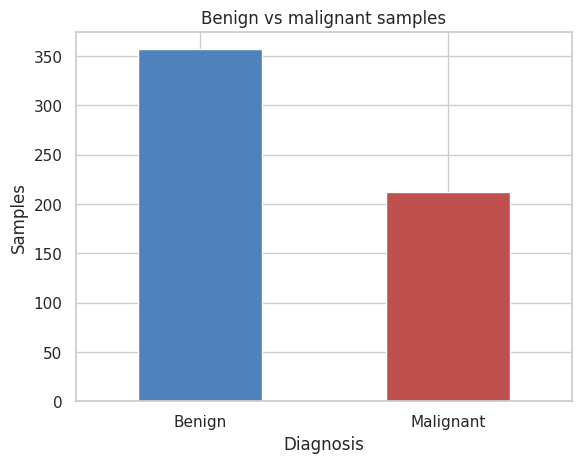

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
df['Diagnosis'].value_counts().plot(kind='bar', color=['#4f81bd', '#c0504d'], rot=0)
plt.title('Benign vs malignant samples')
plt.ylabel('Samples')
plt.show()

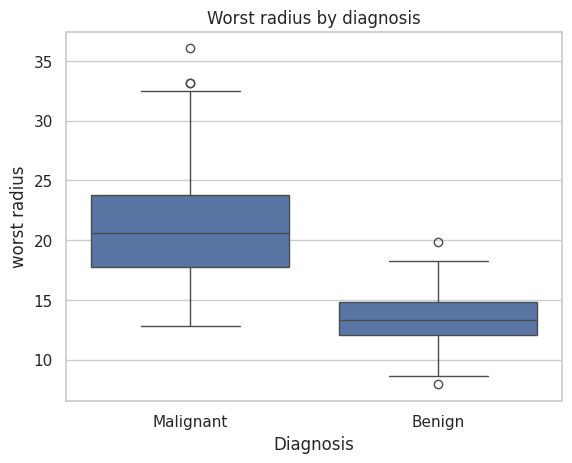

Diagnosis
Benign       13.4
Malignant    21.1
Name: worst radius, dtype: float64


In [6]:
sns.boxplot(data=df, x='Diagnosis', y='worst radius')
plt.title('Worst radius by diagnosis')
plt.show()
print(df.groupby('Diagnosis')['worst radius'].mean().round(1))

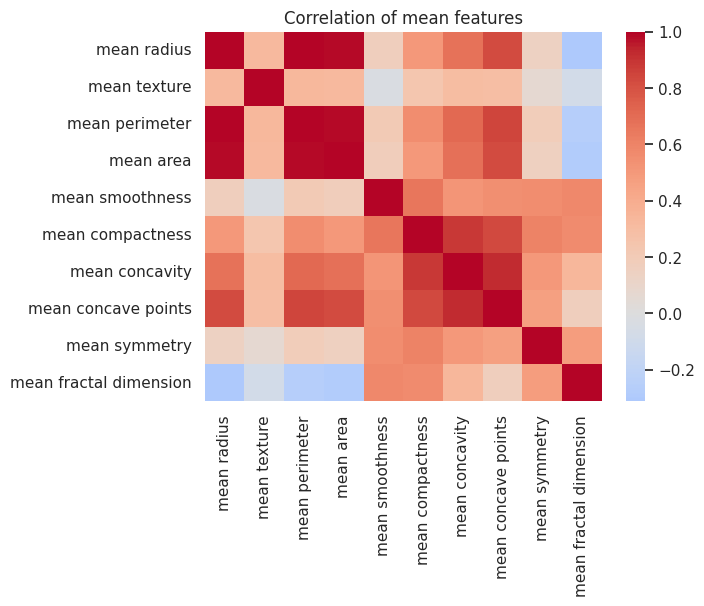

Radius vs area correlation: 0.99


In [7]:
mean_cols = [c for c in df.columns if c.startswith('mean')]
sns.heatmap(df[mean_cols].corr(), cmap='coolwarm', center=0)
plt.title('Correlation of mean features')
plt.show()
print('Radius vs area correlation:', round(df['mean radius'].corr(df['mean area']), 2))

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

X = df[data.feature_names]
y = (df['Diagnosis'] == 'Malignant').astype(int)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xtr, ytr)
print('Test accuracy:', round(model.score(Xte, yte), 3))

Test accuracy: 0.965


## Interpretation

Chart 1 (counts): 357 samples are benign and 212 are malignant, about 37% malignant. The classes are not equal, so accuracy alone can be misleading. It does not tell us why a tumour is malignant.

Chart 2 (worst radius): Malignant samples have a larger average worst radius (about 21.1) than benign samples (about 13.4). This shows a difference between the groups. It does not prove that size alone causes malignancy.

Chart 3 (correlation): Radius and area are almost perfectly correlated (about 0.99), so many features carry the same information. This means individual model coefficients should not be over-interpreted.

Model: Logistic regression reached about 96.5% test accuracy on 143 unseen samples. This is a small curated dataset, so the result may not hold for other labs or patients. It is not a diagnostic tool.

Conclusion: Nucleus size and shape measurements differ clearly between malignant and benign samples, and a simple model separates them well. These charts show patterns, not causes.